# Classificação de pneumonia em radiografias de tórax — v2

Versão revisada de `classificacao_pneumonia_transfer_learning.ipynb`, com o mesmo dataset, a mesma divisão treino/validação (seed 7) e o mesmo conjunto de teste. Mudam o protocolo de treino e a arquitetura.

**Problema da v1:** no teste, 66 dos 234 exames normais foram classificados como pneumonia. A especificidade ficou em 71,8% e a precisão de `PNEUMONIA` em 85,3% (acurácia 88,3%, recall 98,2%). A validação dava F1 macro 0,950, mas o teste deu 0,867. O teste é mais difícil que a validação, que sai do mesmo conjunto do treino. Os pesos de classe favorecem `NORMAL` (1,94 contra 0,67), então não explicam esses falsos positivos. O treino curto (5 épocas, só o `layer4` ajustado) é o ponto mais fácil de atacar.

**Objetivo:** reduzir os falsos positivos sem perder sensibilidade.

**Critério de sucesso (teste):**
- Acurácia acima de 88,3% (v1).
- Precisão de `PNEUMONIA` acima de 85,3% (v1).
- Recall de `PNEUMONIA` de pelo menos 95%.

Uso educacional. O modelo não substitui diagnóstico médico.

In [1]:
# Configuração, imports e reprodutibilidade
from __future__ import annotations

%matplotlib inline

import io
import math
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.compute as pc
import pyarrow.parquet as pq
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from torchvision.transforms import v2

warnings.filterwarnings("ignore", message=r"Detected call of `lr_scheduler\.step\(\)`")

SEED = 7
DATA_DIR = Path(r"C:\Users\soninho\Desktop\_dl_hf_pneumonia")
FIG_DIR = Path("figuras_v2")
FIG_DIR.mkdir(exist_ok=True)

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
CACHE_SIZE = 256          # cada radiografia é decodificada uma vez, em 256x256 tons de cinza
IMG_SIZE = 224
BATCH_SIZE = 32
VAL_FRACTION = 0.15
BACKBONES = ["resnet18", "resnet50"]
EPOCHS_HEAD = 2
EPOCHS_FINETUNE = 12
LR_HEAD = 1e-3
LR_FINETUNE = 1e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
TTA_CROPS = (1.0, 0.9)    # frações do lado da imagem usadas nas visões do TTA

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True

# Cores: séries em ordem fixa, texto em tinta neutra, verde/vermelho só para acerto/erro
SERIES_COLORS = {"resnet18": "#2a78d6", "resnet50": "#eb6834"}
INK, INK_SECONDARY, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
HIT_COLOR, MISS_COLOR = "#006300", "#d03b3b"
SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list(
    "azul_sequencial", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"]
)
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "text.color": INK,
        "xtick.color": INK_MUTED,
        "ytick.color": INK_MUTED,
    }
)


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def pct(value: float) -> str:
    return f"{100 * value:.1f}%".replace(".", ",")


seed_everything()
print("dispositivo:", DEVICE)
if DEVICE.type == "cuda":
    print("gpu:", torch.cuda.get_device_name(0))

dispositivo: cuda
gpu: NVIDIA GeForce RTX 3050 6GB Laptop GPU


## O que muda em relação à v1

| Ponto | v1 | v2 | Motivo |
|---|---|---|---|
| Treino | 3 épocas só na cabeça + 2 épocas liberando o `layer4` | 2 épocas na cabeça + 12 épocas na rede inteira, com aquecimento e taxa de aprendizado em cosseno | Na v1 a rede mal se adaptou às radiografias: o melhor estado foi a 1ª época de ajuste fino |
| Arquitetura | ResNet18 | ResNet18 e ResNet50 (pesos ImageNet), mais a média das duas (ensemble) | Uma rede mais profunda e a combinação de modelos tendem a errar menos em dados um pouco diferentes do treino |
| Aumento de dados | flip horizontal + rotação de 8° | recorte com zoom (70–100% da área), rotação de 10°, translação de 5%, brilho e contraste ±25%, sem flip | Enquadramento e exposição variam entre exames; espelhar a radiografia troca o coração de lado |
| Regularização | nenhuma | label smoothing 0,1, AdamW com weight decay, dropout 0,3 na cabeça | Reduz a confiança excessiva que gera falsos positivos |
| Inferência | 1 visão | média de 2 visões (imagem inteira e recorte central de 90%), se a validação aprovar | O teste com aumento (TTA) estabiliza a probabilidade |
| Velocidade | JPEG decodificado a cada época | decodificação única (cache de 256 px) e precisão mista na GPU | Mais épocas cabem no mesmo tempo |

A divisão treino/validação, a seed, os pesos de classe e o conjunto de teste são os mesmos da v1. O modelo final é escolhido só pela validação, e o teste é avaliado no fim.

In [2]:
# Carrega os bytes das radiografias a partir dos arquivos Parquet (mesma divisão da v1)
def load_parquet_split(pattern: str) -> tuple[list[bytes], np.ndarray]:
    files = sorted(DATA_DIR.glob(pattern))
    if not files:
        raise FileNotFoundError(f"Nenhum arquivo em {DATA_DIR / pattern}")
    images: list[bytes] = []
    labels: list[int] = []
    for path in files:
        table = pq.read_table(path, columns=["image", "label"])
        images.extend(pc.struct_field(table.column("image"), "bytes").to_pylist())
        labels.extend(table.column("label").to_pylist())
    return images, np.asarray(labels, dtype=np.int64)


train_images, train_labels = load_parquet_split("train-*.parquet")
test_images, test_labels = load_parquet_split("test-*.parquet")

train_idx, val_idx = train_test_split(
    np.arange(len(train_labels)),
    test_size=VAL_FRACTION,
    stratify=train_labels,
    random_state=SEED,
)


def counts(labels: np.ndarray) -> dict[str, int]:
    values, freq = np.unique(labels, return_counts=True)
    return {CLASS_NAMES[int(v)]: int(n) for v, n in zip(values, freq)}


dataset_summary = {
    "treino": {"n": int(len(train_idx)), **counts(train_labels[train_idx])},
    "validacao": {"n": int(len(val_idx)), **counts(train_labels[val_idx])},
    "teste": {"n": int(len(test_labels)), **counts(test_labels)},
}
dataset_summary

{'treino': {'n': 4433, 'NORMAL': 1140, 'PNEUMONIA': 3293},
 'validacao': {'n': 783, 'NORMAL': 201, 'PNEUMONIA': 582},
 'teste': {'n': 624, 'NORMAL': 234, 'PNEUMONIA': 390}}

## Cache das imagens

As radiografias originais são grandes, e decodificar cada JPEG a cada época era o gargalo da v1. Aqui cada imagem é decodificada uma única vez, em tons de cinza e 256×256, e fica na memória. O aumento de dados e o redimensionamento final para 224 px partem desse cache.

In [3]:
# Decodifica cada JPEG uma única vez: tons de cinza, 256x256
def decode_gray(data: bytes, size: int = CACHE_SIZE) -> np.ndarray:
    image = Image.open(io.BytesIO(data))
    image.draft("L", (2 * size, 2 * size))  # o decodificador JPEG já entrega a imagem reduzida
    return np.asarray(image.convert("L").resize((size, size), Image.Resampling.BILINEAR), dtype=np.uint8)


start = time.time()
train_cache = torch.from_numpy(np.stack([decode_gray(data) for data in train_images]))
test_x = torch.from_numpy(np.stack([decode_gray(data) for data in test_images]))
test_y = test_labels

train_x = train_cache[torch.from_numpy(train_idx)]
train_y = torch.from_numpy(train_labels[train_idx])
val_x = train_cache[torch.from_numpy(val_idx)]
val_y = train_labels[val_idx]
del train_cache
print(
    f"treino {tuple(train_x.shape)} | validação {tuple(val_x.shape)} | teste {tuple(test_x.shape)} | "
    f"{time.time() - start:.0f} s"
)

treino (4433, 256, 256) | validação (783, 256, 256) | teste (624, 256, 256) | 38 s


## Aumento de dados

Cada lote de treino recebe versões sorteadas das radiografias: recorte com zoom, pequena rotação e translação, brilho e contraste. A validação e o teste não recebem aumento. A grade abaixo mostra uma radiografia e sete versões sorteadas.

In [4]:
class AugmentedXRays(Dataset):
    """Recortes aumentados (uint8, 1x224x224) gerados a partir do cache."""

    def __init__(self, images: torch.Tensor, labels: torch.Tensor, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, index: int):
        return self.transform(self.images[index].unsqueeze(0)), self.labels[index]


# Sem flip horizontal: espelhar a radiografia troca o coração de lado
train_tf = v2.Compose(
    [
        v2.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.85, 1.15), antialias=True),
        v2.RandomAffine(degrees=10, translate=(0.05, 0.05)),
        v2.ColorJitter(brightness=0.25, contrast=0.25),
    ]
)

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def normalize(batch: torch.Tensor) -> torch.Tensor:
    """(B,1,H,W) em 0-255 -> (B,3,H,W) normalizado na GPU; o cinza se repete nos 3 canais do ImageNet."""
    x = batch.to(DEVICE, non_blocking=True).float() / 255
    return (x.expand(-1, 3, -1, -1) - IMAGENET_MEAN) / IMAGENET_STD


def eval_views(batch: torch.Tensor, crops=(1.0,)) -> list[torch.Tensor]:
    """Visões determinísticas para avaliação: recortes centrais redimensionados para IMG_SIZE."""
    x = batch.to(DEVICE, non_blocking=True).float()
    size = x.shape[-1]
    views = []
    for frac in crops:
        side = round(size * frac)
        offset = (size - side) // 2
        crop = x[..., offset : offset + side, offset : offset + side]
        crop = F.interpolate(crop, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", antialias=True, align_corners=False)
        views.append(normalize(crop))
    return views


train_loader = DataLoader(
    AugmentedXRays(train_x, train_y, train_tf),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    generator=torch.Generator().manual_seed(SEED),
)

class_counts = np.bincount(train_labels[train_idx], minlength=len(CLASS_NAMES))
class_weights = class_counts.sum() / (len(CLASS_NAMES) * class_counts)
print("pesos de classe:", {name: round(float(w), 3) for name, w in zip(CLASS_NAMES, class_weights)})
print("lotes por época:", len(train_loader))

pesos de classe: {'NORMAL': 1.944, 'PNEUMONIA': 0.673}
lotes por época: 138


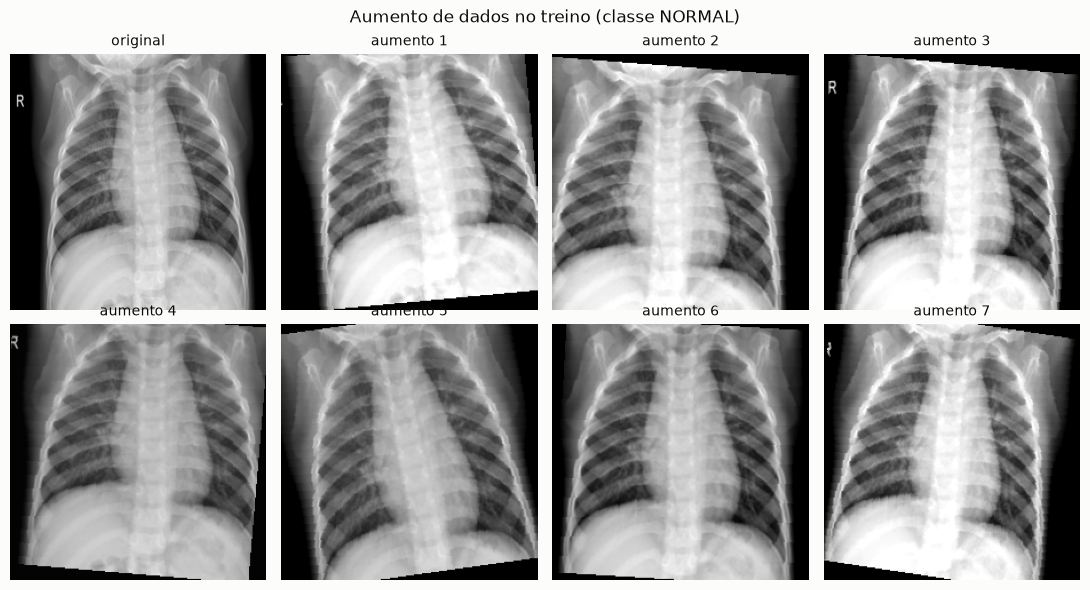

In [5]:
# Uma radiografia de treino e sete versões sorteadas pelo aumento de dados
torch.manual_seed(SEED)
sample = train_x[0].unsqueeze(0)
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for i, ax in enumerate(axes.ravel()):
    image = sample[0] if i == 0 else train_tf(sample)[0]
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title("original" if i == 0 else f"aumento {i}", fontsize=10)
    ax.axis("off")
fig.suptitle(f"Aumento de dados no treino (classe {CLASS_NAMES[int(train_y[0])]})")
fig.tight_layout()
plt.show()

## Modelos e treino

Cada ResNet passa por duas fases:

1. **Cabeça:** a base pré-treinada fica congelada e só a nova camada final (dropout + linear) aprende, com AdamW e taxa 1e-3.
2. **Ajuste fino:** a rede inteira é liberada, com AdamW e taxa 1e-4. A primeira época aquece a taxa e as seguintes a reduzem em cosseno.

A perda é a entropia cruzada com os mesmos pesos de classe da v1 e label smoothing 0,1. O treino usa precisão mista (AMP) na GPU. Ao fim de cada época o modelo é avaliado na validação e o estado guardado é o de maior F1 macro (desempate pela menor log loss).

In [6]:
def binary_scores(truths: np.ndarray, probs: np.ndarray, threshold: float = 0.5) -> dict[str, float]:
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(truths, preds, labels=[0, 1]).ravel()
    return {
        "acuracia": float(accuracy_score(truths, preds)),
        "precisao_pneumonia": float(precision_score(truths, preds, zero_division=0)),
        "recall_pneumonia": float(recall_score(truths, preds, zero_division=0)),
        "especificidade": float(tn / max(tn + fp, 1)),
        "f1_macro": float(f1_score(truths, preds, average="macro", zero_division=0)),
        "auc": float(roc_auc_score(truths, probs)),
        "log_loss": float(log_loss(truths, np.clip(probs, 1e-6, 1 - 1e-6), labels=[0, 1])),
        "vn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "vp": int(tp),
    }


@torch.no_grad()
def predict_proba(model: nn.Module, images: torch.Tensor, crops=(1.0,), batch_size: int = 64) -> np.ndarray:
    """Probabilidade de PNEUMONIA; com TTA, média entre as visões."""
    model.eval()
    probs = []
    for start in range(0, len(images), batch_size):
        batch = images[start : start + batch_size].unsqueeze(1)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            views = [model(view).float().softmax(dim=1)[:, 1] for view in eval_views(batch, crops)]
        probs.append(torch.stack(views).mean(dim=0).cpu().numpy())
    return np.concatenate(probs)


def build_model(name: str) -> nn.Module:
    if name == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    elif name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    else:
        raise ValueError(f"backbone desconhecido: {name}")
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, len(CLASS_NAMES)))
    return model.to(DEVICE)


def train_backbone(name: str) -> tuple[nn.Module, list[dict]]:
    seed_everything()
    train_loader.generator.manual_seed(SEED)
    model = build_model(name)
    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE),
        label_smoothing=LABEL_SMOOTHING,
    )
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    history: list[dict] = []
    best = {"key": (-1.0, -math.inf)}

    def run_phase(phase: str, epochs: int, optimizer, scheduler=None) -> None:
        for epoch in range(1, epochs + 1):
            start = time.time()
            model.train()
            running = torch.zeros((), device=DEVICE)
            for inputs, targets in train_loader:
                inputs, targets = normalize(inputs), targets.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                    loss = criterion(model(inputs), targets)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()
                running += loss.detach()
            train_loss = running.item() / len(train_loader)
            scores = binary_scores(val_y, predict_proba(model, val_x))
            history.append({"modelo": name, "fase": phase, "epoca": len(history) + 1, "loss_treino": train_loss, **scores})
            print(
                f"{name} | {phase} {epoch}/{epochs} | loss treino {train_loss:.4f} | loss val {scores['log_loss']:.4f} | "
                f"acc {scores['acuracia']:.3f} | recall PNEUMONIA {scores['recall_pneumonia']:.3f} | "
                f"f1 macro {scores['f1_macro']:.3f} | {time.time() - start:.0f} s"
            )
            key = (round(scores["f1_macro"], 4), -scores["log_loss"])
            if key > best["key"]:
                best.update(
                    key=key,
                    epoch=len(history),
                    phase=phase,
                    state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                )

    # Fase 1: base congelada, só a cabeça aprende
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.fc.parameters():
        parameter.requires_grad = True
    run_phase("cabeca", EPOCHS_HEAD, torch.optim.AdamW(model.fc.parameters(), lr=LR_HEAD, weight_decay=WEIGHT_DECAY))

    # Fase 2: rede inteira, 1 época de aquecimento e depois decaimento em cosseno
    for parameter in model.parameters():
        parameter.requires_grad = True
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR_FINETUNE, weight_decay=WEIGHT_DECAY)
    warmup, total_steps = len(train_loader), EPOCHS_FINETUNE * len(train_loader)

    def lr_factor(step: int) -> float:
        if step < warmup:
            return 0.1 + 0.9 * step / warmup
        progress = (step - warmup) / max(1, total_steps - warmup)
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * progress))

    run_phase("ajuste_fino", EPOCHS_FINETUNE, optimizer, torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor))

    model.load_state_dict(best["state"])
    print(f"{name}: melhor época {best['epoch']} ({best['phase']}) | f1 macro na validação {best['key'][0]:.4f}")
    return model, history

In [7]:
trained: dict[str, nn.Module] = {}
history_rows: list[dict] = []
for name in BACKBONES:
    model, rows = train_backbone(name)
    trained[name] = model
    history_rows.extend(rows)
history = pd.DataFrame(history_rows)

resnet18 | cabeca 1/2 | loss treino 0.5502 | loss val 0.3729 | acc 0.847 | recall PNEUMONIA 0.808 | f1 macro 0.825 | 17 s


resnet18 | cabeca 2/2 | loss treino 0.4732 | loss val 0.3854 | acc 0.851 | recall PNEUMONIA 0.806 | f1 macro 0.830 | 18 s


resnet18 | ajuste_fino 1/12 | loss treino 0.3999 | loss val 0.2635 | acc 0.916 | recall PNEUMONIA 0.893 | f1 macro 0.898 | 25 s


resnet18 | ajuste_fino 2/12 | loss treino 0.3597 | loss val 0.2667 | acc 0.926 | recall PNEUMONIA 0.902 | f1 macro 0.911 | 27 s


resnet18 | ajuste_fino 3/12 | loss treino 0.3382 | loss val 0.2157 | acc 0.953 | recall PNEUMONIA 0.942 | f1 macro 0.941 | 47 s


...

resnet50 | ajuste_fino 8/12 | loss treino 0.2930 | loss val 0.1858 | acc 0.971 | recall PNEUMONIA 0.966 | f1 macro 0.963 | 45 s


resnet50 | ajuste_fino 9/12 | loss treino 0.2856 | loss val 0.2002 | acc 0.962 | recall PNEUMONIA 0.952 | f1 macro 0.952 | 43 s


resnet50 | ajuste_fino 10/12 | loss treino 0.2838 | loss val 0.1964 | acc 0.966 | recall PNEUMONIA 0.957 | f1 macro 0.956 | 43 s


resnet50 | ajuste_fino 11/12 | loss treino 0.2797 | loss val 0.2051 | acc 0.964 | recall PNEUMONIA 0.954 | f1 macro 0.955 | 43 s


resnet50 | ajuste_fino 12/12 | loss treino 0.2784 | loss val 0.1976 | acc 0.967 | recall PNEUMONIA 0.959 | f1 macro 0.958 | 42 s
resnet50: melhor época 10 (ajuste_fino) | f1 macro na validação 0.9625


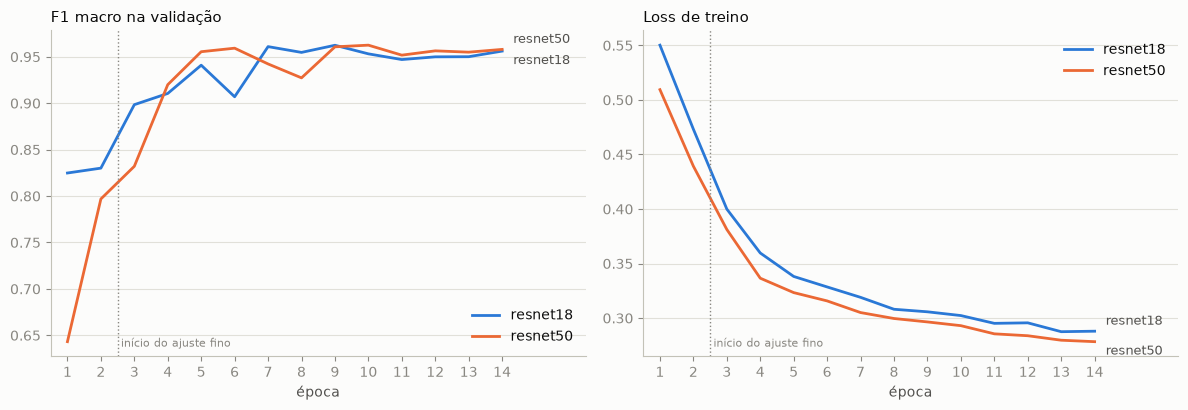

In [8]:
# Curvas por época: F1 macro na validação e loss de treino
n_epochs = EPOCHS_HEAD + EPOCHS_FINETUNE
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (column, title) in zip(axes, [("f1_macro", "F1 macro na validação"), ("loss_treino", "Loss de treino")]):
    ends = {}
    for name in BACKBONES:
        rows = history[history["modelo"] == name]
        ax.plot(rows["epoca"], rows[column], color=SERIES_COLORS[name], linewidth=2, label=name)
        ends[name] = rows[column].iloc[-1]
    top = max(ends, key=ends.get)
    for name, value in ends.items():
        ax.annotate(
            name, (n_epochs, value), xytext=(8, 7 if name == top else -7), textcoords="offset points",
            va="center", color=INK_SECONDARY, fontsize=9,
        )
    ax.axvline(EPOCHS_HEAD + 0.5, color=INK_MUTED, linewidth=1, linestyle=":")
    ax.text(EPOCHS_HEAD + 0.6, 0.03, "início do ajuste fino", transform=ax.get_xaxis_transform(), color=INK_MUTED, fontsize=8)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("época")
    ax.set_xlim(0.5, n_epochs + 2.5)
    ax.set_xticks(range(1, n_epochs + 1))
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "curvas_treino.png", dpi=150, bbox_inches="tight")
plt.show()

## Escolha do modelo final

Seis candidatos: ResNet18, ResNet50 e o ensemble (média das probabilidades das duas), cada um com e sem TTA. Vence o maior F1 macro na validação, com desempate pela menor log loss. O conjunto de teste não participa da escolha.

In [9]:
CANDIDATES = [{"modelo": name, "tta": tta} for name in [*BACKBONES, "ensemble"] for tta in (False, True)]


def candidate_label(candidate: dict) -> str:
    return f"{candidate['modelo']} {'com' if candidate['tta'] else 'sem'} TTA"


def candidate_proba(candidate: dict, images: torch.Tensor) -> np.ndarray:
    names = BACKBONES if candidate["modelo"] == "ensemble" else [candidate["modelo"]]
    crops = TTA_CROPS if candidate["tta"] else (1.0,)
    return np.mean([predict_proba(trained[name], images, crops) for name in names], axis=0)


val_table = pd.DataFrame.from_dict(
    {candidate_label(c): binary_scores(val_y, candidate_proba(c, val_x)) for c in CANDIDATES}, orient="index"
)
final = max(
    CANDIDATES,
    key=lambda c: (round(val_table.loc[candidate_label(c), "f1_macro"], 4), -val_table.loc[candidate_label(c), "log_loss"]),
)
FINAL_LABEL = candidate_label(final)
print("modelo final, escolhido na validação:", FINAL_LABEL)
val_table[["acuracia", "precisao_pneumonia", "recall_pneumonia", "especificidade", "f1_macro", "auc", "log_loss"]].round(4)

modelo final, escolhido na validação: ensemble com TTA


,acuracia,precisao_pneumonia,recall_pneumonia,especificidade,f1_macro,auc,log_loss
resnet18 sem TTA,0.9706,0.9929,0.9674,0.9801,0.9624,0.9962,0.1734
resnet18 com TTA,0.9745,0.9930,0.9725,0.9801,0.9672,0.9971,0.1576
resnet50 sem TTA,0.9706,0.9947,0.9656,0.9851,0.9625,0.9973,0.1858
resnet50 com TTA,0.9757,0.9896,0.9777,0.9701,0.9686,0.9978,0.1662
ensemble sem TTA,0.9693,0.9947,0.9639,0.9851,0.9610,0.9976,0.1751
ensemble com TTA,0.9770,0.9913,0.9777,0.9751,0.9703,0.9980,0.1594


## Avaliação no teste

O limiar é 0,5 sobre a probabilidade de pneumonia, equivalente ao `argmax` da v1. O teste só é usado aqui.

In [10]:
test_prob = candidate_proba(final, test_x)
test_pred = (test_prob >= 0.5).astype(int)
test_metrics = binary_scores(test_y, test_prob)
print(f"modelo: {FINAL_LABEL}\n")
print(classification_report(test_y, test_pred, target_names=CLASS_NAMES, digits=3))
{key: round(value, 4) for key, value in test_metrics.items()}

modelo: ensemble com TTA

              precision    recall  f1-score   support

      NORMAL      0.981     0.872     0.923       234
   PNEUMONIA      0.928     0.990     0.958       390

    accuracy                          0.946       624
   macro avg      0.954     0.931     0.940       624
weighted avg      0.948     0.946     0.945       624



{'acuracia': 0.9455,
 'precisao_pneumonia': 0.9279,
 'recall_pneumonia': 0.9897,
 'especificidade': 0.8718,
 'f1_macro': 0.9404,
 'auc': 0.9894,
 'log_loss': 0.1999,
 'vn': 204,
 'fp': 30,
 'fn': 4,
 'vp': 386}

## Matriz de confusão

Linhas são a classe real e colunas a classe predita. O percentual é relativo à linha: na linha `NORMAL`, VN% é a especificidade; na linha `PNEUMONIA`, VP% é o recall.

- Falso negativo (FN): pneumonia real classificada como `NORMAL`. É o erro mais grave, porque um caso doente passaria como saudável.
- Falso positivo (FP): exame normal classificado como `PNEUMONIA`. Foi o erro dominante na v1.

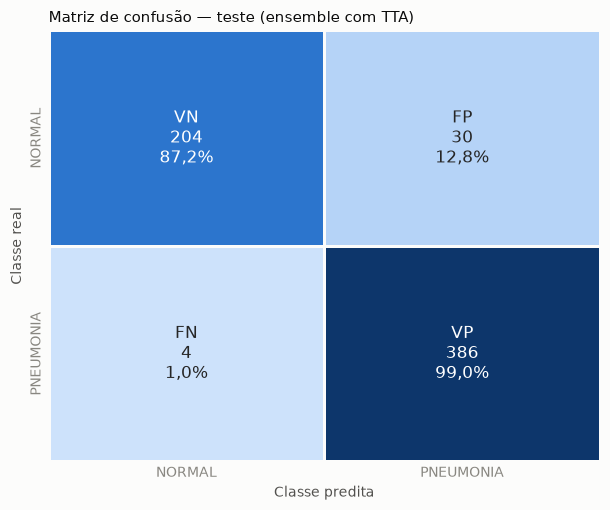

{'verdadeiros_negativos': 204,
 'falsos_positivos': 30,
 'falsos_negativos': 4,
 'verdadeiros_positivos': 386}

In [11]:
cm = confusion_matrix(test_y, test_pred, labels=[0, 1])
row_share = cm / cm.sum(axis=1, keepdims=True)
tags = [["VN", "FP"], ["FN", "VP"]]
annotations = np.array([[f"{tags[i][j]}\n{cm[i, j]}\n{pct(row_share[i, j])}" for j in range(2)] for i in range(2)])

fig, ax = plt.subplots(figsize=(6.2, 5.2))
sns.heatmap(
    cm,
    annot=annotations,
    fmt="",
    cmap=SEQUENTIAL_BLUE,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=False,
    linewidths=2,
    linecolor="#fcfcfb",
    annot_kws={"fontsize": 12},
    ax=ax,
)
ax.set_xlabel("Classe predita")
ax.set_ylabel("Classe real")
ax.set_title(f"Matriz de confusão — teste ({FINAL_LABEL})", loc="left", fontsize=11)
ax.tick_params(length=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
confusion_summary = {
    "verdadeiros_negativos": int(tn),
    "falsos_positivos": int(fp),
    "falsos_negativos": int(fn),
    "verdadeiros_positivos": int(tp),
}
confusion_summary

## Mosaico de predições

Grade com amostras do teste. O título traz a classe real, a classe predita e `p`, a probabilidade de pneumonia dada pelo modelo. Verde com ✓ indica acerto e vermelho com ✗ indica erro, então a leitura não depende só da cor. Como na v1, a seleção mistura acertos e erros para os dois casos aparecerem.

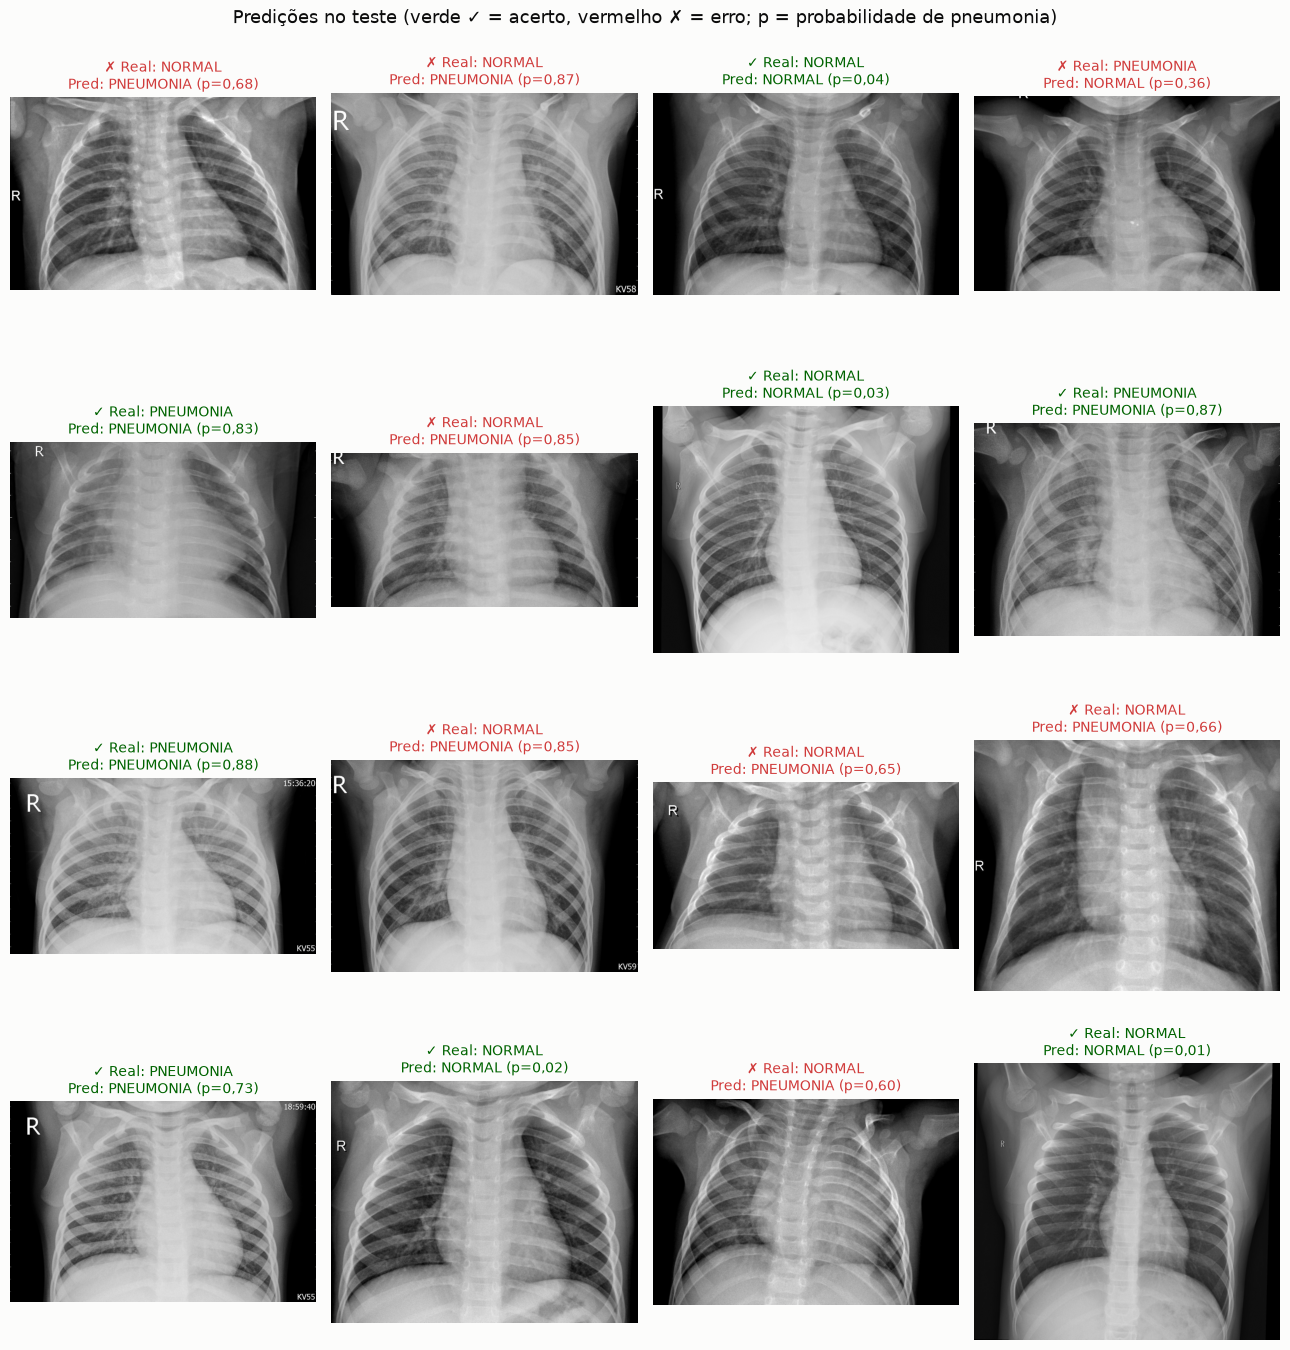

acertos na grade: 8 | erros na grade: 8


In [12]:
rng = np.random.default_rng(SEED)
correct = np.flatnonzero(test_y == test_pred)
wrong = np.flatnonzero(test_y != test_pred)
n_wrong = min(8, len(wrong))
n_correct = min(16 - n_wrong, len(correct))
chosen = np.concatenate(
    [
        rng.choice(wrong, size=n_wrong, replace=False) if n_wrong else np.array([], dtype=int),
        rng.choice(correct, size=n_correct, replace=False),
    ]
)
rng.shuffle(chosen)

fig, axes = plt.subplots(4, 4, figsize=(13, 14))
for ax in axes.ravel():
    ax.axis("off")
for ax, index in zip(axes.ravel(), chosen):
    image = Image.open(io.BytesIO(test_images[int(index)]))
    image.draft("L", (512, 512))
    real = CLASS_NAMES[int(test_y[index])]
    pred = CLASS_NAMES[int(test_pred[index])]
    hit = real == pred
    ax.imshow(image.convert("L"), cmap="gray")
    title = f"{'✓' if hit else '✗'} Real: {real}\nPred: {pred} (p={test_prob[index]:.2f})".replace(".", ",")
    ax.set_title(title, color=HIT_COLOR if hit else MISS_COLOR, fontsize=10)

fig.suptitle("Predições no teste (verde ✓ = acerto, vermelho ✗ = erro; p = probabilidade de pneumonia)", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "mosaico_predicoes.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"acertos na grade: {n_correct} | erros na grade: {n_wrong}")

## Comparação com a v1

Métricas no teste. A linha da v1 traz os valores do notebook original. Das linhas da v2, a marcada foi escolhida pela validação; as outras ficam como referência e não serviram para a escolha.

In [13]:
V1_TEST = {
    "acuracia": 0.8830,
    "precisao_pneumonia": 0.8530,
    "recall_pneumonia": 0.9821,
    "especificidade": 168 / 234,
    "f1_macro": 0.8673,
    "vn": 168,
    "fp": 66,
    "fn": 7,
    "vp": 383,
}
rows = {"v1: resnet18 (notebook original)": V1_TEST}
for candidate in CANDIDATES:
    label = f"v2: {candidate_label(candidate)}" + ("  ← escolhido" if candidate is final else "")
    rows[label] = binary_scores(test_y, candidate_proba(candidate, test_x))
comparison = pd.DataFrame.from_dict(rows, orient="index")
comparison[
    ["acuracia", "precisao_pneumonia", "recall_pneumonia", "especificidade", "f1_macro", "vn", "fp", "fn", "vp"]
].round(4)

,acuracia,precisao_pneumonia,recall_pneumonia,especificidade,f1_macro,vn,fp,fn,vp
v1: resnet18 (notebook original),0.8830,0.8530,0.9821,0.7179,0.8673,168,66,7,383
v2: resnet18 sem TTA,0.9551,0.9436,0.9872,0.9017,0.9513,211,23,5,385
v2: resnet18 com TTA,0.9407,0.9212,0.9897,0.8590,0.9350,201,33,4,386
v2: resnet50 sem TTA,0.9439,0.9340,0.9795,0.8846,0.9391,207,27,8,382
v2: resnet50 com TTA,0.9423,0.9255,0.9872,0.8675,0.9369,203,31,5,385
v2: ensemble sem TTA,0.9551,0.9436,0.9872,0.9017,0.9513,211,23,5,385
v2: ensemble com TTA ← escolhido,0.9455,0.9279,0.9897,0.8718,0.9404,204,30,4,386


## Resultados

O modelo final, escolhido na validação, é o **ensemble ResNet18 + ResNet50 com TTA**. No teste:

| Métrica | v1 | v2 |
|---|---|---|
| Acurácia | 88,3% | **94,6%** |
| Precisão de `PNEUMONIA` | 85,3% | **92,8%** |
| Recall de `PNEUMONIA` | 98,2% | **99,0%** |
| Especificidade | 71,8% | **87,2%** |
| F1 macro | 0,867 | **0,940** |
| Falsos positivos | 66 | **30** |
| Falsos negativos | 7 | **4** |

- Os três critérios de sucesso foram atingidos. Os falsos positivos caíram para menos da metade, e os falsos negativos também diminuíram.
- O maior ganho veio do protocolo de treino, não da arquitetura. A ResNet18 sozinha, treinada como na v2, chega a 94,1–95,5% de acurácia no teste, contra 88,3% na v1.
- O TTA melhorou a validação (F1 macro do ensemble de 0,961 para 0,970), mas não o teste: sem TTA o ensemble teria 23 falsos positivos em vez de 30. O resultado oficial continua sendo o escolhido pela validação, porque trocar a escolha depois de ver o teste deixaria a métrica otimista.
- A distância entre validação e teste diminuiu (F1 macro 0,970 contra 0,940; na v1 era 0,950 contra 0,867), mas não sumiu. O teste continua mais difícil que a validação.
- A execução completa levou cerca de 18 minutos numa RTX 3050 Laptop (6 GB). Com `cudnn.benchmark` ligado, uma nova execução pode variar um pouco nas últimas casas.

Os gráficos estão em `figuras_v2/`: `matriz_confusao.png`, `mosaico_predicoes.png` e `curvas_treino.png`.

In [14]:
result = {
    "seed": SEED,
    "modelo_final": FINAL_LABEL,
    "f1_macro_validacao": round(float(val_table.loc[FINAL_LABEL, "f1_macro"]), 4),
    **{f"teste_{key}": round(value, 4) for key, value in test_metrics.items()},
}
result

{'seed': 7,
 'modelo_final': 'ensemble com TTA',
 'f1_macro_validacao': 0.9703,
 'teste_acuracia': 0.9455,
 'teste_precisao_pneumonia': 0.9279,
 'teste_recall_pneumonia': 0.9897,
 'teste_especificidade': 0.8718,
 'teste_f1_macro': 0.9404,
 'teste_auc': 0.9894,
 'teste_log_loss': 0.1999,
 'teste_vn': 204,
 'teste_fp': 30,
 'teste_fn': 4,
 'teste_vp': 386}

## Próximos passos

- **TTA:** ajudou na validação e não no teste. Vale testar outras visões, ou removê-lo, decidindo com dados novos.
- **Limiar de decisão:** mover o corte de 0,5 troca falsos positivos por falsos negativos. Esse ajuste precisa de dados parecidos com o teste, e a validação atual sai do conjunto de treino.
- **Resolução maior** (320 a 384 px) para lesões pequenas, ao custo de mais tempo de GPU.
- **VGG16** no mesmo protocolo, já que o enunciado cita a rede.
- **Outras seeds** para medir quanto as métricas variam entre execuções.